# Imports

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading CSV's

In [16]:
municipalCaseParties = pd.read_csv('municipal_case_parties.csv')
popInfo = pd.read_csv('municipal_population_2000_2024.csv')

In [17]:
#GATEWAY CITIES TO REFERENCE BACK TO
gateway_cities = [
    'Attleboro', 'Barnstable', 'Brockton', 'Chelsea', 'Chicopee',
    'Everett', 'Fall River', 'Fitchburg', 'Haverhill', 'Holyoke',
    'Lawrence', 'Leominster', 'Lowell', 'Lynn', 'Malden',
    'Methuen', 'New Bedford', 'Peabody', 'Pittsfield', 'Quincy',
    'Revere', 'Salem', 'Springfield', 'Taunton', 'Westfield', 'Worcester'
]

#Cleaning

In [18]:
# Ensure file_date is datetime and extract year for municipalCaseParties if not already done
municipalCaseParties['file_date'] = pd.to_datetime(municipalCaseParties['file_date'], errors='coerce')
municipalCaseParties['year'] = municipalCaseParties['file_date'].dt.year

# Filter municipalCaseParties for years between 2006 and 2024
municipalCaseParties = municipalCaseParties[(municipalCaseParties['year'] >= 2006) & (municipalCaseParties['year'] <= 2024)]

# Filter popInfo for years between 2006 and 2024
popInfo = popInfo[(popInfo['year'] >= 2006) & (popInfo['year'] <= 2024)]


In [19]:
municipalCaseParties = municipalCaseParties[municipalCaseParties['party_type'].astype(str).str.lower().str.contains('defendant', na=False)]

In [20]:
# Show unique values in the case type column
# Let's inspect columns first to find the exact case type column name if it contains spaces or underscores
case_type_col = [col for col in municipalCaseParties.columns if 'case' in col.lower() and 'type' in col.lower()]
if case_type_col:
    print(f"Unique values in '{case_type_col[0]}':")
    print(municipalCaseParties[case_type_col[0]].unique())
else:
    # Fallback to standard column lookup
    print(municipalCaseParties['case_type'].unique())

Unique values in 'case_type':
['Administrative Civil Actions' 'Civil' 'Small Claims'
 'Actions Involving the State/Municipality' 'Permit Session'
 'Miscellaneous' 'Real Property' 'Housing Court Civil'
 'Equitable Remedies' 'Torts' 'Contract / Business Cases' 'Other Court'
 'Subsequent' 'Tax Lien' 'Servicemembers'
 'Civil Actions with Incarcerated Party' 'Equity Complaint'
 'Business Litigation' 'Parentage in Equity' 'Summary Process' 'Criminal'
 'Housing Court Summary Process' 'Housing Court Small Claims'
 'Supplementary Process']


In [21]:
category_mapping = {
    'Housing Court Civil': 'Housing',
    'Housing Court Small Claims': 'Housing',
    'Housing Court Summary Process': 'Housing',
    'Summary Process': 'Housing',
    'Civil': 'Civil',
    'Administrative Civil Actions': 'Civil',
    'Miscellaneous Civil Actions': 'Civil',
    'Civil Actions with Incarcerated Party': 'Civil',
    'Small Claims': 'Small Claims',
    'Actions Involving the State/Municipality': 'State/Municipality',
    'Permit Session': 'Permit',
    'Real Property': 'Real Property',
    'Equitable Remedies': 'Equity/Remedies',
    'Equity Petition': 'Equity/Remedies',
    'Equity Complaint': 'Equity/Remedies',
    'Equity - Partition': 'Equity/Remedies',
    'Parentage in Equity': 'Equity/Remedies',
    'Contract / Business Cases': 'Business/Contract',
    'Business Litigation': 'Business/Contract',
    'Torts': 'Torts',
    'Tax Lien': 'Tax/Financial',
    'Servicemembers': 'Special Sessions',
    'Supplementary Process': 'Civil',
    'Subsequent': 'Other',
    'Other Court': 'Other',
    'Miscellaneous': 'Other',
    'Administrative Appeals': 'Administrative',
    'Criminal': 'Criminal',
    'Criminal Complaint': 'Criminal',
    'Indictment': 'Criminal',
    'Estates and Administration': 'Probate/Estate',
    'Probate Other': 'Probate/Estate'
}

municipalCaseParties['case_category'] = municipalCaseParties['case_type'].map(category_mapping).fillna('Other')

display(municipalCaseParties[['case_type', 'case_category']].drop_duplicates().head(15))
print("\nCase category value counts:")
display(municipalCaseParties['case_category'].value_counts())

,case_type,case_category
4,Administrative Civil Actions,Civil
9,Civil,Civil
12,Small Claims,Small Claims
26,Actions Involving the State/Municipality,State/Municipality
27,Permit Session,Permit
34,Miscellaneous,Other
126,Real Property,Real Property
196,Housing Court Civil,Housing
280,Equitable Remedies,Equity/Remedies
634,Torts,Torts



Case category value counts:


,count
case_category,
State/Municipality,6173
Civil,5922
Real Property,3391
Torts,2315
Other,2281
Equity/Remedies,1682
Tax/Financial,1395
Small Claims,1033
Business/Contract,631


In [22]:
# Create a copy of the dataset
enriched_case_parties = municipalCaseParties.copy()

# Safely ensure the 'is_gateway' column is created and populated on the fly
gateway_set = {g.strip().lower() for g in gateway_cities}
enriched_case_parties['muni_key'] = enriched_case_parties['municipality'].astype(str).str.strip().str.lower()
enriched_case_parties['is_gateway'] = enriched_case_parties['muni_key'].apply(lambda x: 'Gateway City' if x in gateway_set else 'Non-Gateway City')

# Save the complete enriched dataset to a new CSV file
enriched_case_parties.to_csv('municipal_case_parties_enriched.csv', index=False)

print("Enriched dataset successfully created and saved as 'municipal_case_parties_enriched.csv'.")

# Safely display the columns including 'is_gateway'
columns_to_display = ['municipality', 'case_type', 'case_category', 'is_gateway']

Enriched dataset successfully created and saved as 'municipal_case_parties_enriched.csv'.


# Plotting

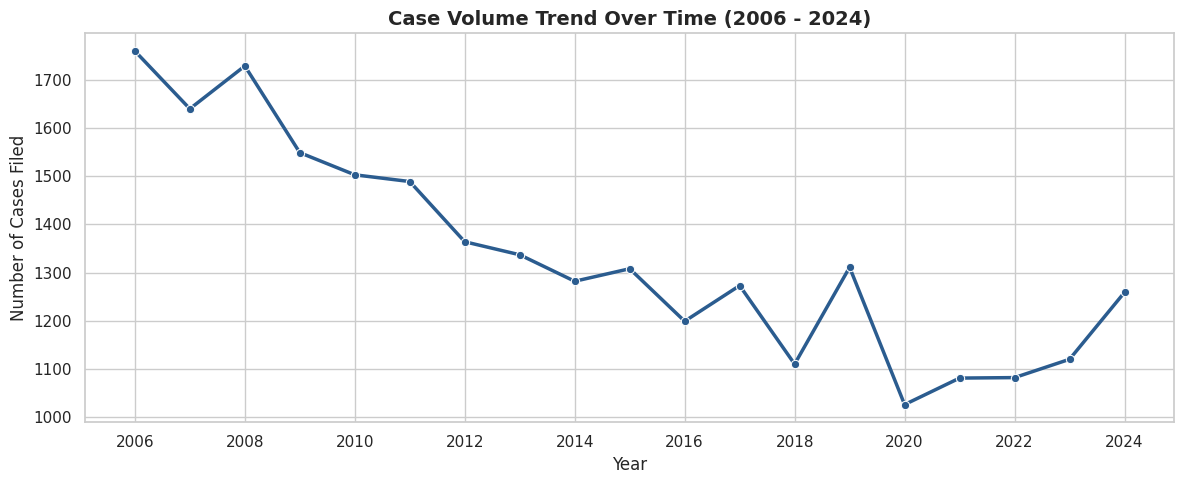

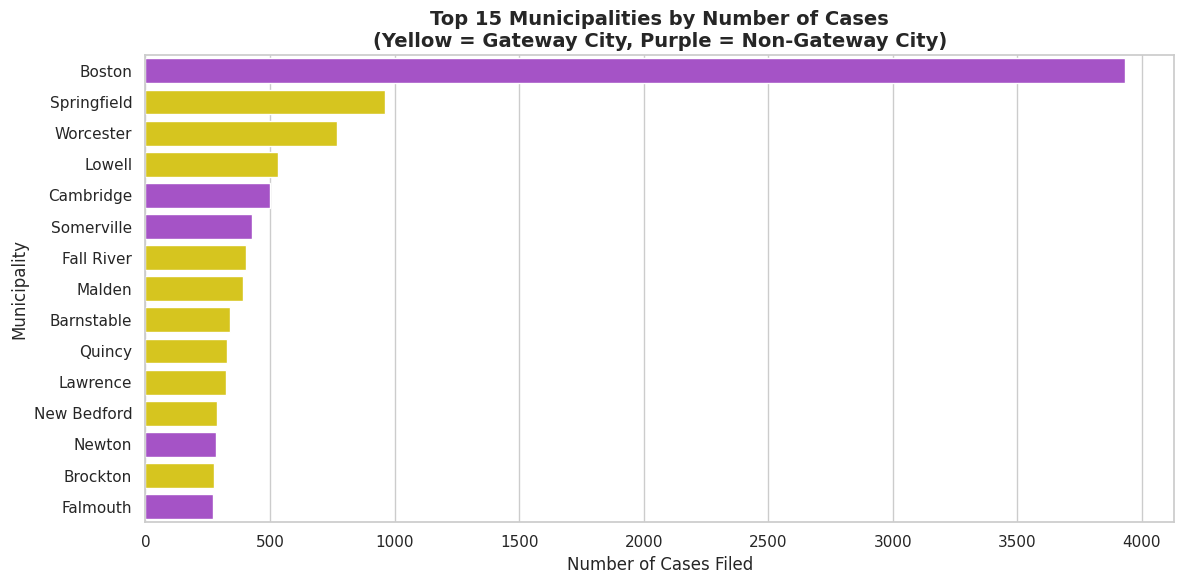

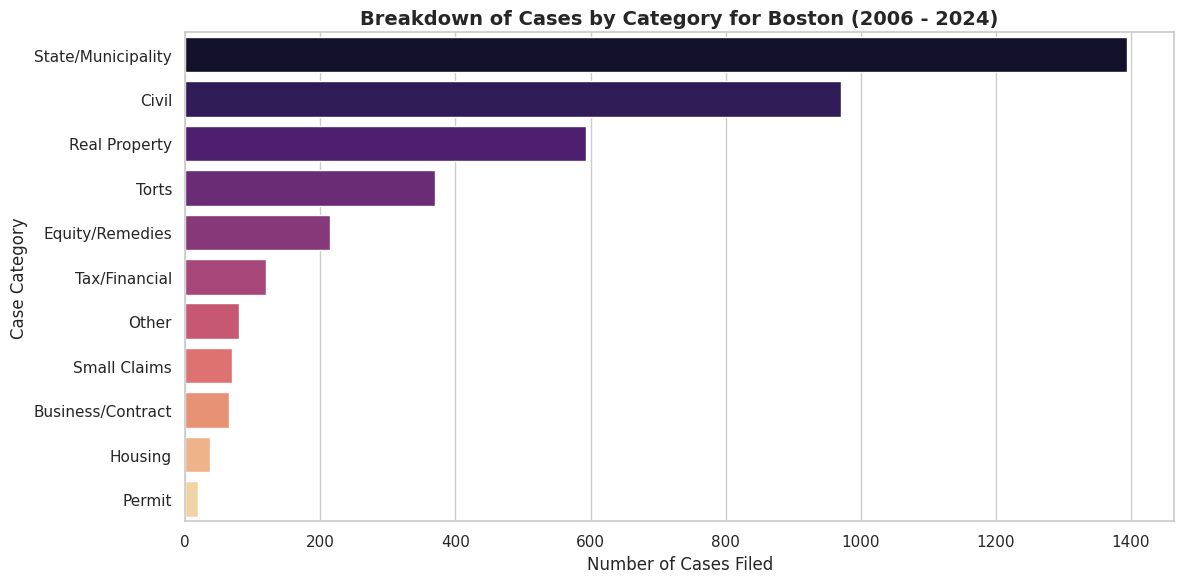

In [23]:
# Set plotting style
sns.set_theme(style="whitegrid")

# Drop any rows with invalid/null years for clean time trends
time_df = municipalCaseParties.dropna(subset=['year'])
time_df = time_df[(time_df['year'] >= 2006) & (time_df['year'] <= 2024)]

# Plot 1: Trends Over Time (Annual Case Volume)
plt.figure(figsize=(12, 5))
yearly_counts = time_df['year'].value_counts().sort_index()
sns.lineplot(x=yearly_counts.index, y=yearly_counts.values, marker='o', color='#2b5c8f', linewidth=2.5)
plt.title('Case Volume Trend Over Time (2006 - 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Cases Filed', fontsize=12)
plt.xticks(np.arange(2006, 2025, 2))
plt.tight_layout()
plt.show()

# Plot 2: Top 15 Municipalities by Case Count with Gateway Cities Color-Coding
plt.figure(figsize=(12, 6))
top_municipalities = municipalCaseParties['municipality'].value_counts().head(15)

# Map colors dynamically: Gateway Cities are '#F5DE00', others are '#AD40D9'
colors = [
    '#F5DE00' if m.strip().title() in [g.title() for g in gateway_cities] else '#AD40D9'
    for m in top_municipalities.index
]

sns.barplot(
    x=top_municipalities.values,
    y=top_municipalities.index,
    hue=top_municipalities.index,
    palette=colors,
    legend=False
)
plt.title('Top 15 Municipalities by Number of Cases\n(Yellow = Gateway City, Purple = Non-Gateway City)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Cases Filed', fontsize=12)
plt.ylabel('Municipality', fontsize=12)
plt.tight_layout()
plt.show()

# Plot 3: Breakdown of Case Types (Case Categories) for Boston
plt.figure(figsize=(12, 6))
boston_cases = municipalCaseParties[municipalCaseParties['municipality'].astype(str).str.lower() == 'boston']
boston_category_counts = boston_cases['case_category'].value_counts()

sns.barplot(x=boston_category_counts.values, y=boston_category_counts.index, hue=boston_category_counts.index, palette='magma', legend=False)
plt.title('Breakdown of Cases by Category for Boston (2006 - 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Cases Filed', fontsize=12)
plt.ylabel('Case Category', fontsize=12)
plt.tight_layout()
plt.show()

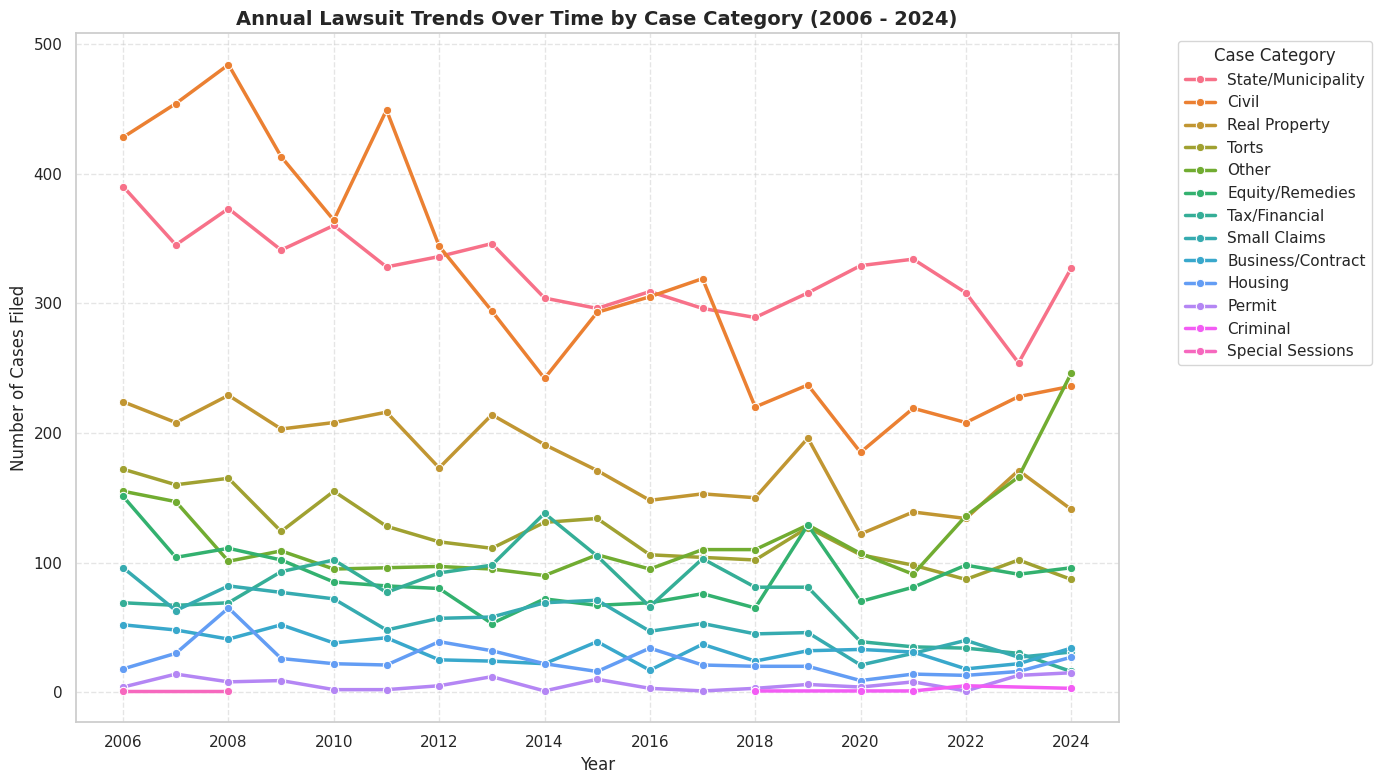

In [24]:
# Group the raw data by case category and year
category_trends = municipalCaseParties.groupby(['case_category', 'year']).size().reset_index(name='case_count')

# Sort categories by total volume to show the most prominent ones in the legend
top_categories = municipalCaseParties['case_category'].value_counts().index

plt.figure(figsize=(14, 8))
sns.lineplot(
    data=category_trends,
    x='year',
    y='case_count',
    hue='case_category',
    hue_order=top_categories,
    marker='o',
    linewidth=2.5
)

plt.title('Annual Lawsuit Trends Over Time by Case Category (2006 - 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Cases Filed', fontsize=12)
plt.xticks(np.arange(2006, 2025, 2))
plt.legend(title='Case Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Per 10,000 Residents

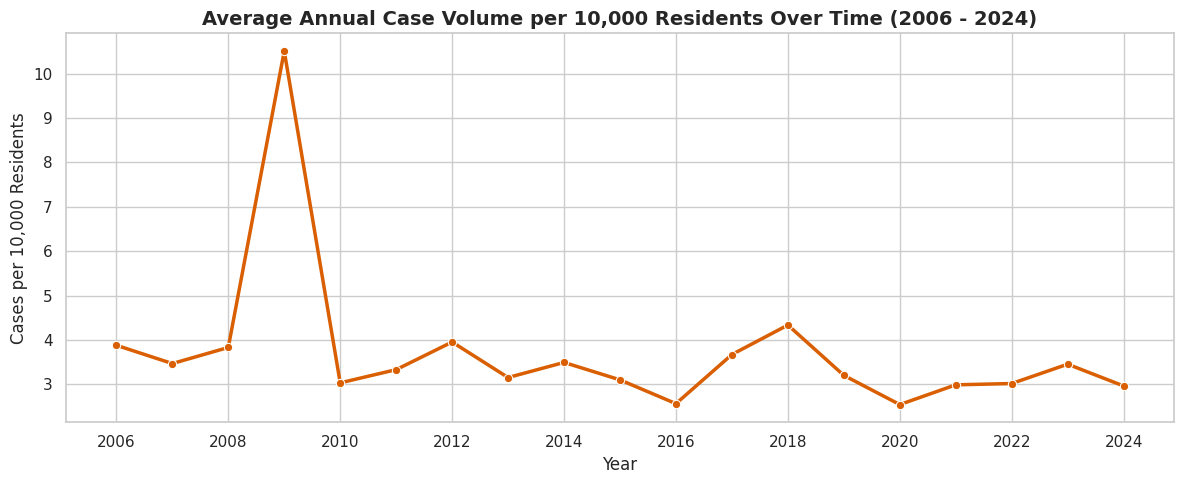

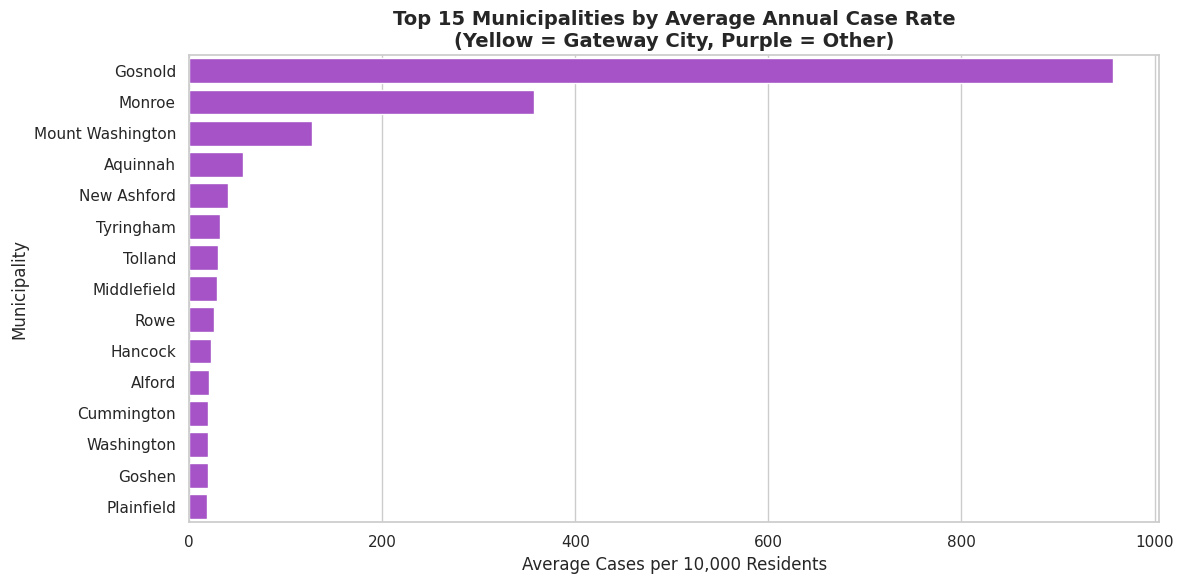

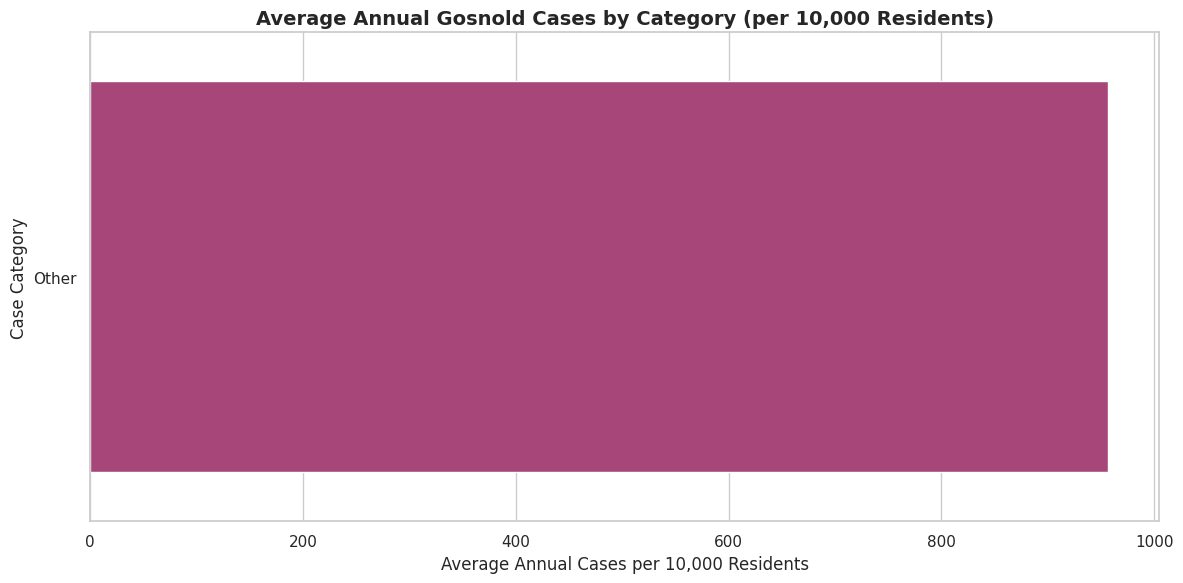

In [25]:
# Ensure clean, lowercase matching keys for municipalities
municipalCaseParties['muni_key'] = municipalCaseParties['municipality'].astype(str).str.strip().str.lower()
popInfo['muni_key'] = popInfo['municipality'].astype(str).str.strip().str.lower()

# 1. Group case counts by municipality and year
yearly_muni_cases = municipalCaseParties.groupby(['muni_key', 'year']).size().reset_index(name='case_count')

# 2. Merge with population info to get matching population for each year
normalized_df = pd.merge(
    yearly_muni_cases,
    popInfo[['muni_key', 'year', 'population', 'municipality']],
    on=['muni_key', 'year'],
    how='inner'
)

# 3. Calculate cases per 10,000 residents
normalized_df['cases_per_10k'] = (normalized_df['case_count'] / normalized_df['population']) * 10000

# --- Plot 1: Trend Over Time (Average Case Rate across all municipalities) ---
plt.figure(figsize=(12, 5))
yearly_rate = normalized_df.groupby('year')['cases_per_10k'].mean()
sns.lineplot(x=yearly_rate.index, y=yearly_rate.values, marker='o', color='#d95f02', linewidth=2.5)
plt.title('Average Annual Case Volume per 10,000 Residents Over Time (2006 - 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Cases per 10,000 Residents', fontsize=12)
plt.xticks(np.arange(2006, 2025, 2))
plt.tight_layout()
plt.show()

# --- Plot 2: Top 15 Municipalities by Average Case Rate with Gateway Cities Color-Coding ---
plt.figure(figsize=(12, 6))
muni_avg_rate = normalized_df.groupby('municipality')['cases_per_10k'].mean().sort_values(ascending=False).head(15)

# Map colors dynamically: Gateway Cities are '#F5DE00', others are '#AD40D9'
colors = [
    '#F5DE00' if m.strip().title() in [g.title() for g in gateway_cities] else '#AD40D9'
    for m in muni_avg_rate.index
]

sns.barplot(
    x=muni_avg_rate.values,
    y=muni_avg_rate.index,
    hue=muni_avg_rate.index,
    palette=colors,
    legend=False
)
plt.title('Top 15 Municipalities by Average Annual Case Rate\n(Yellow = Gateway City, Purple = Other)', fontsize=14, fontweight='bold')
plt.xlabel('Average Cases per 10,000 Residents', fontsize=12)
plt.ylabel('Municipality', fontsize=12)
plt.tight_layout()
plt.show()

# --- Plot 3: Gosnold Case Category Breakdown Normalized (per 10,000 Residents) ---
# Get Gosnold's annual population
Gosnold_pop = popInfo[popInfo['muni_key'] == 'gosnold'].groupby('year')['population'].first().reset_index()

# Group Gosnold cases by category and year
Gosnold_cat_yearly = municipalCaseParties[municipalCaseParties['muni_key'] == 'gosnold'].groupby(['case_category', 'year']).size().reset_index(name='case_count')

# Merge with Boston population
Gosnold_normalized = pd.merge(Gosnold_cat_yearly, Gosnold_pop, on='year', how='inner')
Gosnold_normalized['cases_per_10k'] = (Gosnold_normalized['case_count'] / Gosnold_normalized['population']) * 10000

# Find the average annual rate per category for Gosnold
Gosnold_cat_rate = Gosnold_normalized.groupby('case_category')['cases_per_10k'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=Gosnold_cat_rate.values, y=Gosnold_cat_rate.index, hue=Gosnold_cat_rate.index, palette='magma', legend=False)
plt.title('Average Annual Gosnold Cases by Category (per 10,000 Residents)', fontsize=14, fontweight='bold')
plt.xlabel('Average Annual Cases per 10,000 Residents', fontsize=12)
plt.ylabel('Case Category', fontsize=12)
plt.tight_layout()
plt.show()

In [26]:
# Ensure we have the gateway cities set for quick lookup
gateway_set = {g.strip().lower() for g in gateway_cities}

# 1. Group case counts by municipality and year
yearly_muni_cases = municipalCaseParties.groupby(['muni_key', 'year']).size().reset_index(name='case_count')

# 2. Merge with annual population to get exact population figures
spreadsheet_df = pd.merge(
    yearly_muni_cases,
    popInfo[['muni_key', 'year', 'population', 'municipality']],
    on=['muni_key', 'year'],
    how='inner'
)

# 3. Dynamically assign the 'is_gateway' classification safely
spreadsheet_df['is_gateway'] = spreadsheet_df['muni_key'].apply(
    lambda x: 'Gateway City' if x in gateway_set else 'Non-Gateway City'
)

# 4. Calculate Rate Metrics
# Per Capita Rate (Cases / Population)
spreadsheet_df['cases_per_capita'] = spreadsheet_df['case_count'] / spreadsheet_df['population']

# Standardized rate per 10,000 residents
spreadsheet_df['cases_per_10k_residents'] = spreadsheet_df['cases_per_capita'] * 10000

# 5. Clean up columns and sort for presentation
spreadsheet_df = spreadsheet_df[[
    'municipality', 'year', 'population', 'case_count',
    'cases_per_capita', 'cases_per_10k_residents', 'is_gateway'
]].sort_values(by=['municipality', 'year'])


Spreadsheet successfully generated and saved as 'municipal_lawsuit_rates_per_capita.csv'!


,municipality,year,population,case_count,cases_per_capita,cases_per_10k_residents,is_gateway
0,Abington,2006,16378,7,0.000427,4.274026,Non-Gateway City
1,Abington,2007,16365,4,0.000244,2.444241,Non-Gateway City
2,Abington,2008,16689,1,0.000060,0.599197,Non-Gateway City
3,Abington,2009,16789,2,0.000119,1.191256,Non-Gateway City
4,Abington,2010,15985,1,0.000063,0.625586,Non-Gateway City
5,Abington,2011,16042,2,0.000125,1.246727,Non-Gateway City
6,Abington,2012,16060,1,0.000062,0.622665,Non-Gateway City
7,Abington,2013,16124,1,0.000062,0.620194,Non-Gateway City
8,Abington,2014,16179,2,0.000124,1.236170,Non-Gateway City
9,Abington,2015,16227,1,0.000062,0.616257,Non-Gateway City


In [27]:
import pandas as pd

# Load both previously generated spreadsheets
enriched_parties = pd.read_csv('municipal_case_parties_enriched.csv')
rates_per_capita = pd.read_csv('municipal_lawsuit_rates_per_capita.csv')

# Ensure we have consistent matching keys
enriched_parties['muni_key'] = enriched_parties['municipality'].astype(str).str.strip().str.lower()
rates_per_capita['muni_key'] = rates_per_capita['municipality'].astype(str).str.strip().str.lower()

# Identify columns in the rates spreadsheet to join (avoiding duplicate municipality/is_gateway columns)
rates_cols_to_join = ['muni_key', 'year', 'population', 'cases_per_capita', 'cases_per_10k_residents']

# Merge the datasets together
combined_df = pd.merge(
    enriched_parties,
    rates_per_capita[rates_cols_to_join],
    on=['muni_key', 'year'],
    how='inner'
)

# Drop the helper join key
combined_df = combined_df.drop(columns=['muni_key'])

# Save the combined master dataset to a new CSV file
combined_df.to_csv('municipal_cases_with_population_rates.csv', index=False)

print("Datasets successfully merged!")
print(f"Combined dataset shape: {combined_df.shape[0]} rows, {combined_df.shape[1]} columns.")


Datasets successfully merged!
Combined dataset shape: 25422 rows, 19 columns.


,dor_code,municipality,case_id,case_number,case_title,case_type,file_date,party_id,party_name,party_type,municipal_relationship,match_confidence,procedural_designation,year,case_category,is_gateway,population,cases_per_capita,cases_per_10k_residents
0,165,Malden,2401,1081CV00884,1081CV00884 Dotolo v Malden,Administrative Civil Actions,2010-03-08,4363,City Of Malden,Defendant,direct,high,NaN,2010,Civil,Gateway City,59450,0.000488,4.878049
1,88,Easton,3286,1431CV000075,1431CV000075 Trustees of the Landsdowne Villag...,Civil,2014-01-31,5984,Town of Easton,Defendant,direct,high,NaN,2014,Civil,Non-Gateway City,23640,0.000338,3.384095
2,149,Lawrence,4770,1418SC000213,"1418SC000213 Fiorino, Ellen L. v. City Of Lawr...",Small Claims,2014-01-17,8649,City Of Lawrence,Defendant,direct,high,NaN,2014,Small Claims,Gateway City,79535,0.000302,3.017539
3,236,Pittsfield,5584,1427CV000091,"1427CV000091 Bressette, Stephanie vs. City of ...",Civil,2014-02-20,10094,City of Pittsfield,Defendant,direct,high,NaN,2014,Civil,Gateway City,43655,0.000092,0.916275
4,207,Newton,9855,1081CV01079,1081CV01079 Commerce Insurance Company a/s/o J...,Actions Involving the State/Municipality,2010-03-22,17531,City Of Newton,Defendant,direct,high,NaN,2010,State/Municipality,Non-Gateway City,85146,0.000176,1.761680


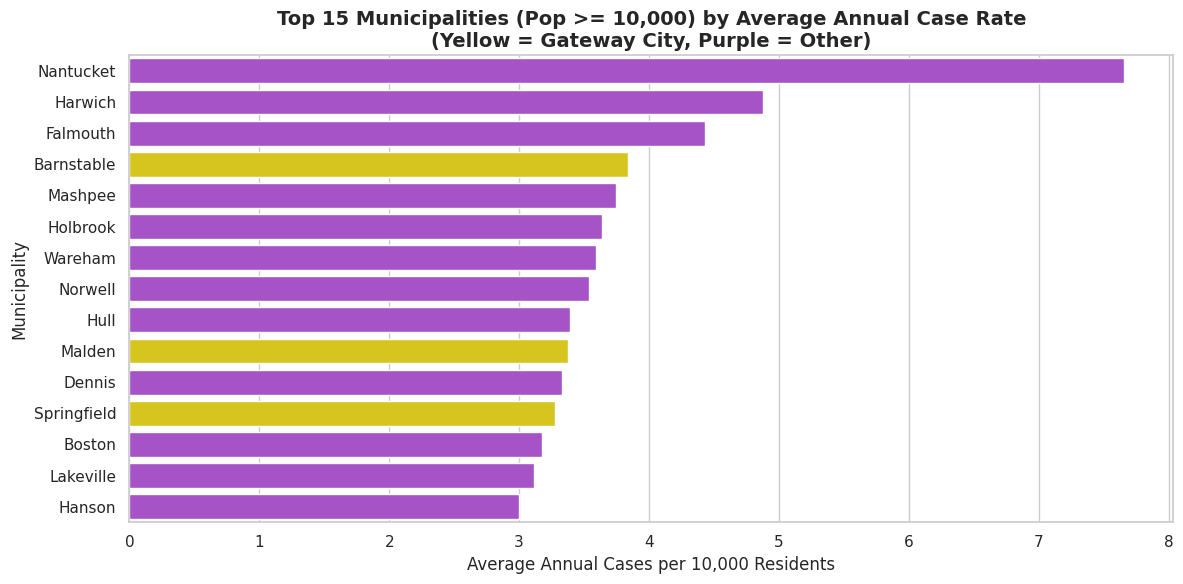

In [28]:
# Calculate overall average annual cases and population per municipality
muni_stats = normalized_df.groupby('municipality').agg(
    avg_annual_cases=('case_count', 'mean'),
    avg_population=('population', 'mean')
).reset_index()

# Apply the minimum population threshold (population >= 10,000)
threshold = 10000
filtered_muni_stats = muni_stats[muni_stats['avg_population'] >= threshold].copy()
filtered_muni_stats['cases_per_10k_filtered'] = (filtered_muni_stats['avg_annual_cases'] / filtered_muni_stats['avg_population']) * 10000

# Identify top 15 municipalities
top_filtered = filtered_muni_stats.sort_values(by='cases_per_10k_filtered', ascending=False).head(15)

# Plot: Top 15 Municipalities (Filtered >= 10k Pop) with Gateway Cities Color-Coding
plt.figure(figsize=(12, 6))

# Map colors dynamically: Gateway Cities are '#F5DE00', others are '#AD40D9'
colors = [
    '#F5DE00' if m.strip().title() in [g.title() for g in gateway_cities] else '#AD40D9'
    for m in top_filtered['municipality']
]

sns.barplot(
    x='cases_per_10k_filtered',
    y='municipality',
    data=top_filtered,
    hue='municipality',
    palette=colors,
    legend=False
)

plt.title('Top 15 Municipalities (Pop >= 10,000) by Average Annual Case Rate\n(Yellow = Gateway City, Purple = Other)', fontsize=14, fontweight='bold')
plt.xlabel('Average Annual Cases per 10,000 Residents', fontsize=12)
plt.ylabel('Municipality', fontsize=12)
plt.tight_layout()
plt.show()

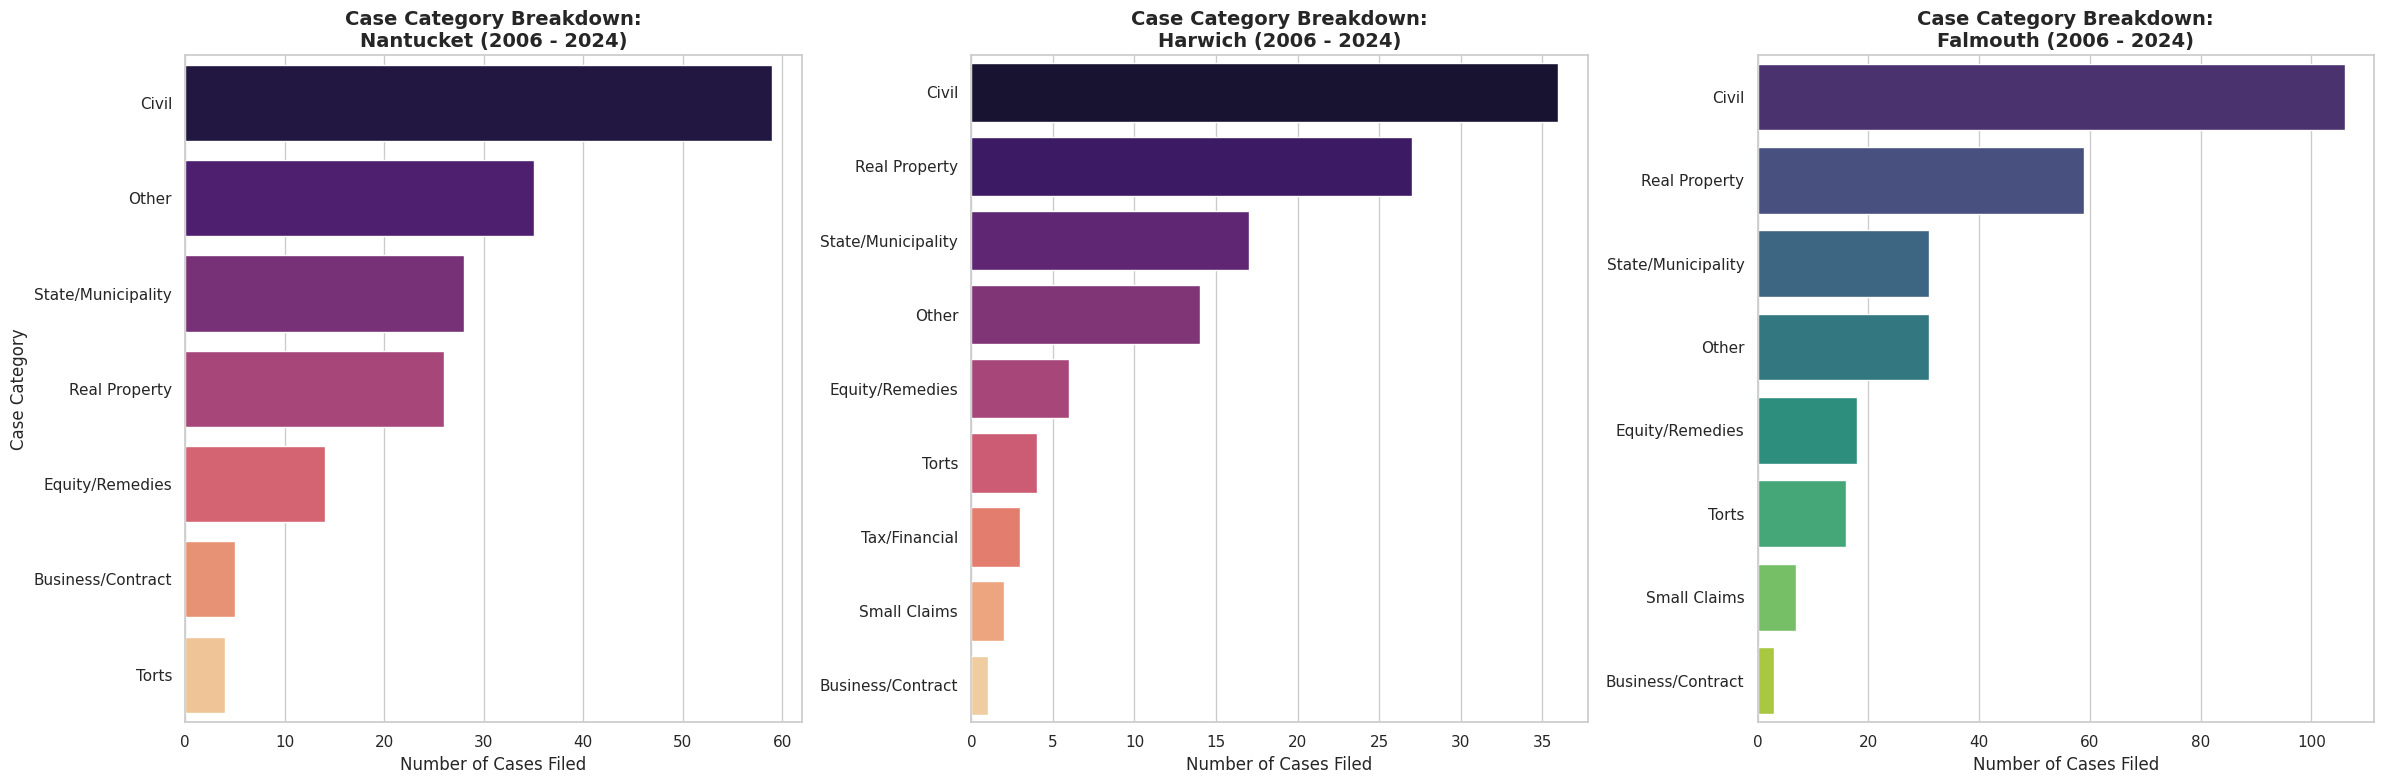

In [29]:
# --- Category Breakdown for Nantucket, Harwich, and Falmouth ---
import matplotlib.pyplot as plt
import seaborn as sns

# Filter and count categories for Nantucket (#1)
nantucket_cases = municipalCaseParties[municipalCaseParties['municipality'].astype(str).str.lower() == 'nantucket']
nantucket_counts = nantucket_cases['case_category'].value_counts()

# Filter and count categories for Harwich (#2)
harwich_cases = municipalCaseParties[municipalCaseParties['municipality'].astype(str).str.lower() == 'harwich']
harwich_counts = harwich_cases['case_category'].value_counts()

# Filter and count categories for Falmouth (#3)
falmouth_cases = municipalCaseParties[municipalCaseParties['municipality'].astype(str).str.lower() == 'falmouth']
falmouth_counts = falmouth_cases['case_category'].value_counts()

# Set up the plotting environment with 3 subplots side-by-side
fig, axes = plt.subplots(1, 3, figsize=(24, 8), sharex=False)

# Plot 1: Nantucket Breakdown
sns.barplot(
    x=nantucket_counts.values,
    y=nantucket_counts.index,
    hue=nantucket_counts.index,
    palette='magma',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Case Category Breakdown:\nNantucket (2006 - 2024)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Cases Filed', fontsize=12)
axes[0].set_ylabel('Case Category', fontsize=12)

# Plot 2: Harwich Breakdown
sns.barplot(
    x=harwich_counts.values,
    y=harwich_counts.index,
    hue=harwich_counts.index,
    palette='magma',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Case Category Breakdown:\nHarwich (2006 - 2024)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Cases Filed', fontsize=12)
axes[1].set_ylabel('', fontsize=12)

# Plot 3: Falmouth Breakdown
sns.barplot(
    x=falmouth_counts.values,
    y=falmouth_counts.index,
    hue=falmouth_counts.index,
    palette='viridis',
    legend=False,
    ax=axes[2]
)
axes[2].set_title('Case Category Breakdown:\nFalmouth (2006 - 2024)', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Number of Cases Filed', fontsize=12)
axes[2].set_ylabel('', fontsize=12)

plt.tight_layout()
plt.show()

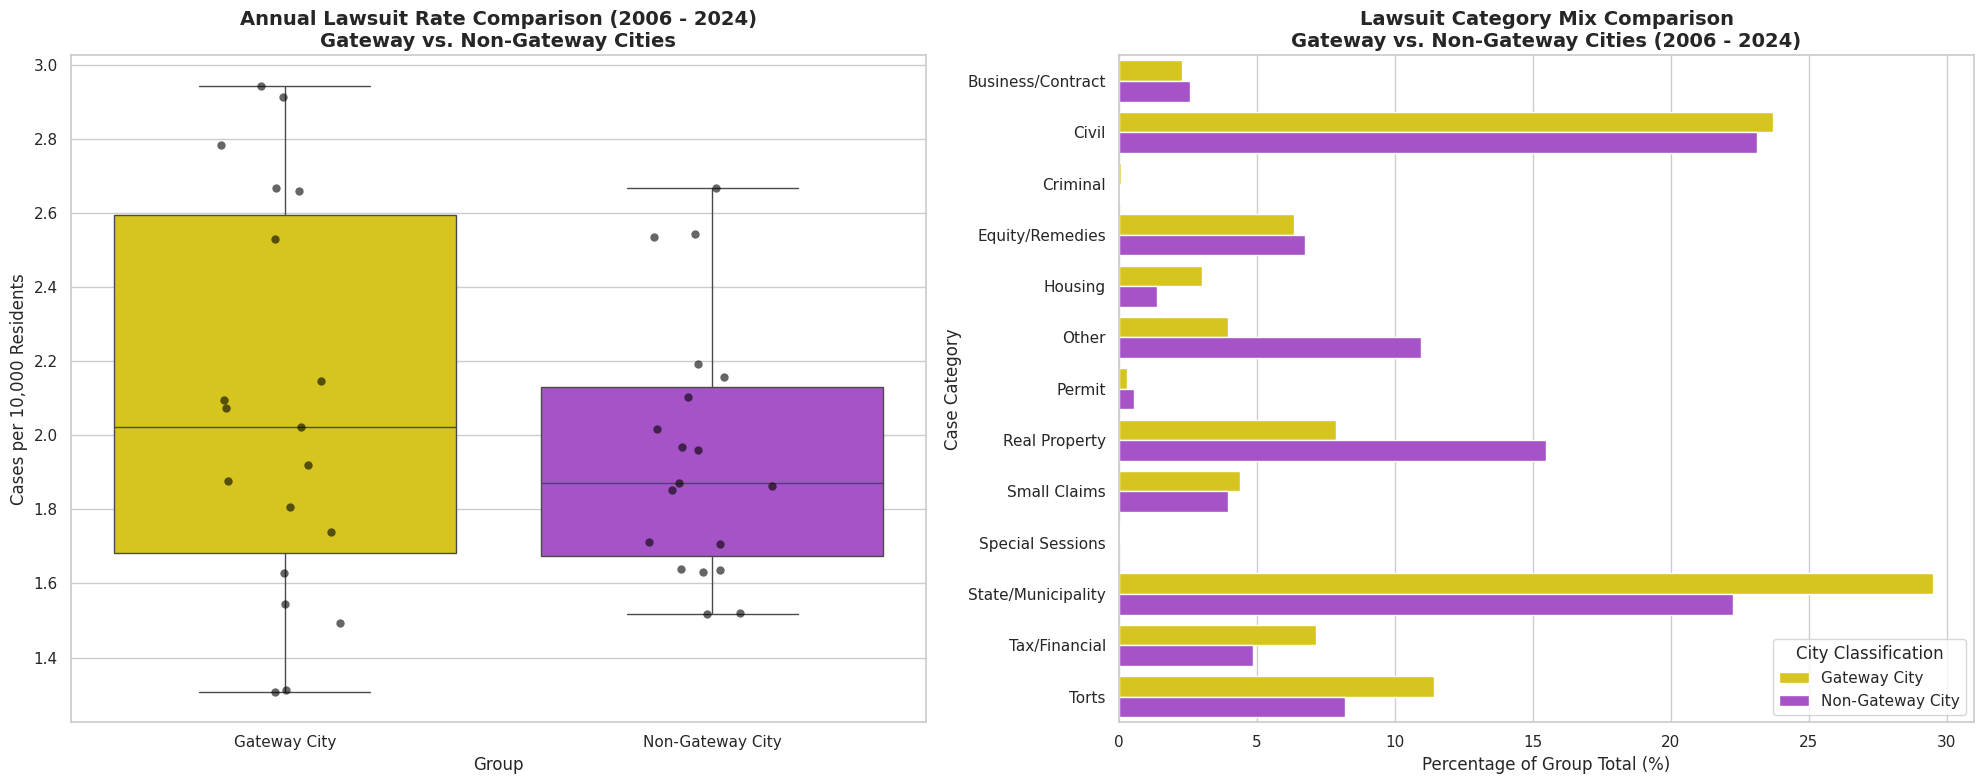

In [30]:
# --- 1. Label Municipalities as Gateway vs Non-Gateway ---
gateway_set = {g.strip().lower() for g in gateway_cities}

municipalCaseParties['muni_key'] = municipalCaseParties['municipality'].astype(str).str.strip().str.lower()
municipalCaseParties['is_gateway'] = municipalCaseParties['muni_key'].apply(lambda x: 'Gateway City' if x in gateway_set else 'Non-Gateway City')

popInfo['muni_key'] = popInfo['municipality'].astype(str).str.strip().str.lower()
popInfo['is_gateway'] = popInfo['muni_key'].apply(lambda x: 'Gateway City' if x in gateway_set else 'Non-Gateway City')

# --- 2. Calculate Case Mix (Percentages) by Category ---
category_mix = municipalCaseParties.groupby(['is_gateway', 'case_category']).size().reset_index(name='case_count')
category_mix['percentage'] = category_mix.groupby('is_gateway')['case_count'].transform(lambda x: (x / x.sum()) * 100)

# --- 3. Compute Population-Normalized Annual Case Rates ---
# Sum annual cases per group
group_yearly_cases = municipalCaseParties.groupby(['is_gateway', 'year']).size().reset_index(name='case_count')
# Sum annual population per group
group_yearly_pop = popInfo.groupby(['is_gateway', 'year'])['population'].sum().reset_index()

# Merge and normalize
group_normalized = pd.merge(group_yearly_cases, group_yearly_pop, on=['is_gateway', 'year'])
group_normalized['cases_per_10k'] = (group_normalized['case_count'] / group_normalized['population']) * 10000

# --- Plotting Visualizations ---
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Plot A: Annual Lawsuits Rate Comparison
sns.boxplot(
    data=group_normalized,
    x='is_gateway',
    y='cases_per_10k',
    ax=axes[0],
    palette={'Gateway City': '#F5DE00', 'Non-Gateway City': '#AD40D9'},
    hue='is_gateway',
    legend=False
)
sns.stripplot(
    data=group_normalized,
    x='is_gateway',
    y='cases_per_10k',
    ax=axes[0],
    color='black',
    alpha=0.6,
    size=6,
    jitter=0.15
)
axes[0].set_title('Annual Lawsuit Rate Comparison (2006 - 2024)\nGateway vs. Non-Gateway Cities', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Group', fontsize=12)
axes[0].set_ylabel('Cases per 10,000 Residents', fontsize=12)

# Plot B: Lawsuit Mix Comparison (Percentage Breakdown)
sns.barplot(
    data=category_mix,
    x='percentage',
    y='case_category',
    hue='is_gateway',
    ax=axes[1],
    palette={'Gateway City': '#F5DE00', 'Non-Gateway City': '#AD40D9'}
)
axes[1].set_title('Lawsuit Category Mix Comparison\nGateway vs. Non-Gateway Cities (2006 - 2024)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Percentage of Group Total (%)', fontsize=12)
axes[1].set_ylabel('Case Category', fontsize=12)
axes[1].legend(title='City Classification')

plt.tight_layout()
plt.show()

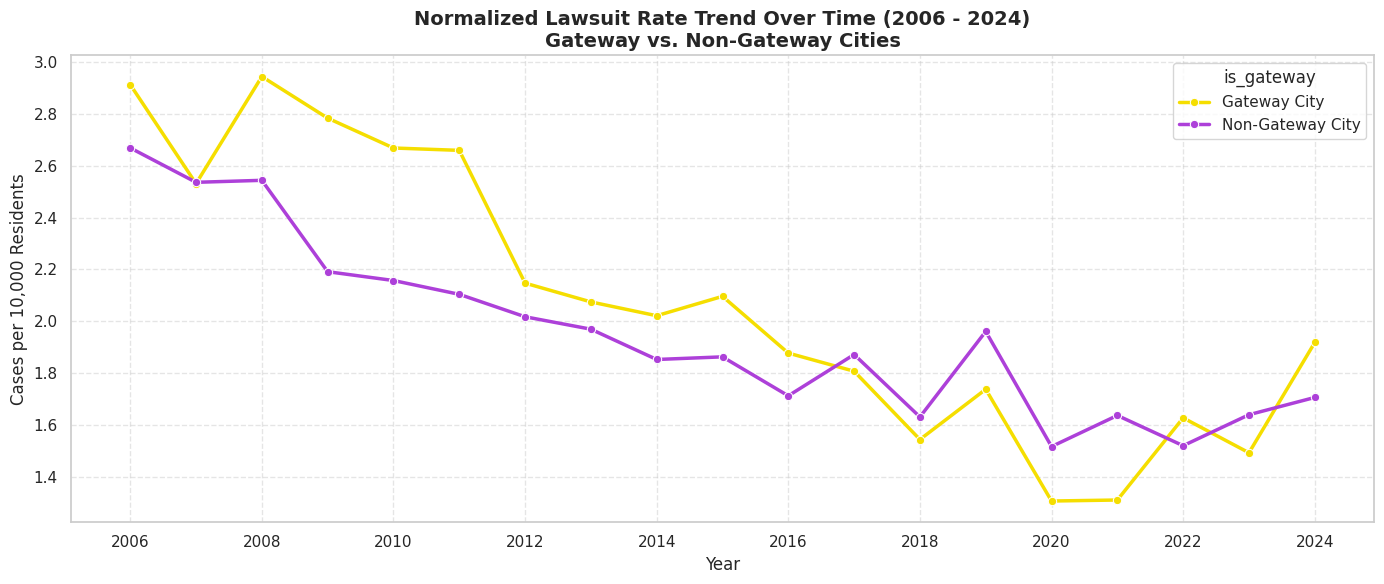

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# --- Visual 1: Time Series Trend of Normalized Case Rates ---
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=group_normalized,
    x='year',
    y='cases_per_10k',
    hue='is_gateway',
    marker='o',
    linewidth=2.5,
    palette={'Gateway City': '#F5DE00', 'Non-Gateway City': '#AD40D9'}
)
plt.title('Normalized Lawsuit Rate Trend Over Time (2006 - 2024)\nGateway vs. Non-Gateway Cities', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Cases per 10,000 Residents', fontsize=12)
plt.xticks(np.arange(2006, 2025, 2))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

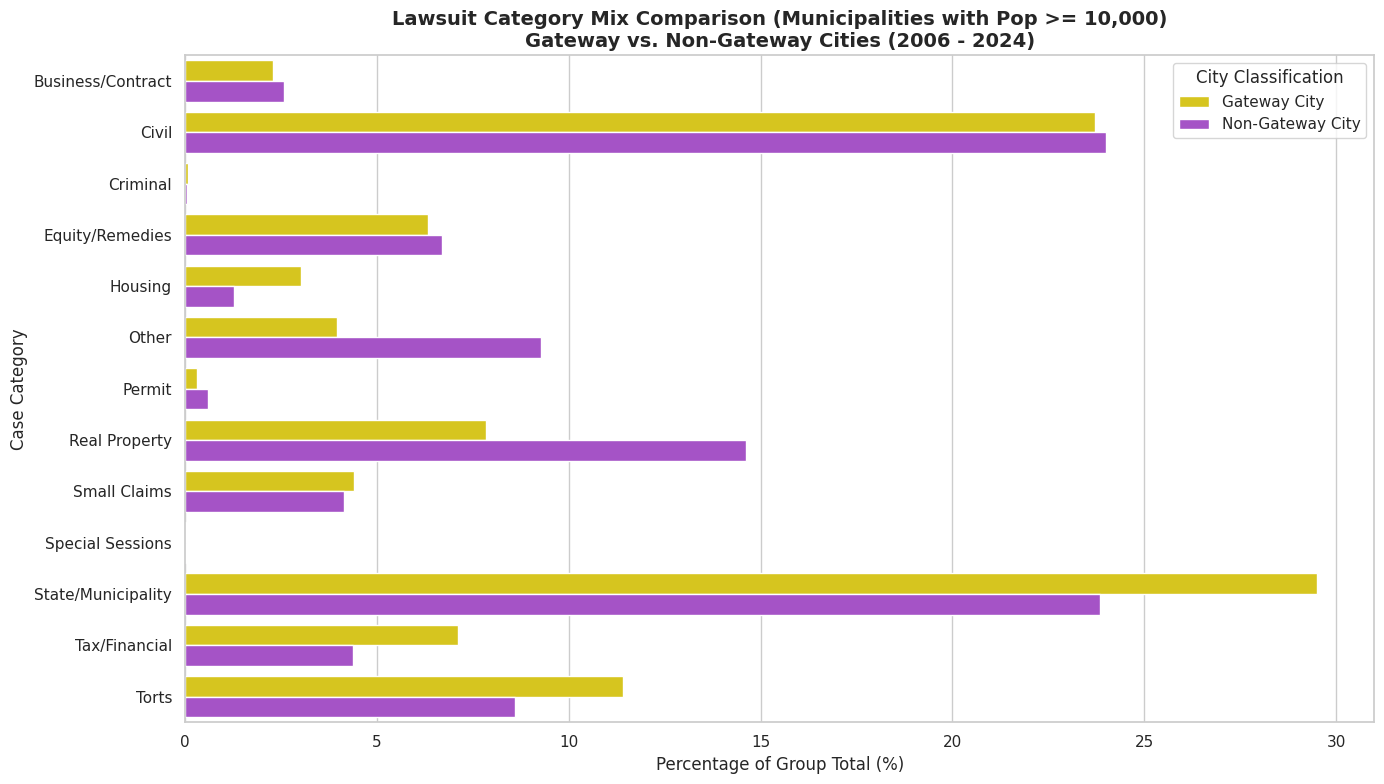

In [32]:
# --- Visual 2: Proportional Case Mix for Municipalities with Pop >= 10,000 ---
# Filter case data to only include municipalities that average >= 10,000 population
pop_10k_muni_keys = filtered_muni_stats['municipality'].astype(str).str.strip().str.lower()
filtered_parties_10k = municipalCaseParties[municipalCaseParties['muni_key'].isin(pop_10k_muni_keys)]

# Calculate proportional mix within this subset
category_mix_10k = filtered_parties_10k.groupby(['is_gateway', 'case_category']).size().reset_index(name='case_count')
category_mix_10k['percentage'] = category_mix_10k.groupby('is_gateway')['case_count'].transform(lambda x: (x / x.sum()) * 100)

plt.figure(figsize=(14, 8))
sns.barplot(
    data=category_mix_10k,
    x='percentage',
    y='case_category',
    hue='is_gateway',
    palette={'Gateway City': '#F5DE00', 'Non-Gateway City': '#AD40D9'}
)
plt.title('Lawsuit Category Mix Comparison (Municipalities with Pop >= 10,000)\nGateway vs. Non-Gateway Cities (2006 - 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Percentage of Group Total (%)', fontsize=12)
plt.ylabel('Case Category', fontsize=12)
plt.legend(title='City Classification')
plt.tight_layout()
plt.show()

In [33]:
# Identify statistical outliers in terms of population-normalized lawsuit rates (Pop >= 10,000)
q1 = filtered_muni_stats['cases_per_10k_filtered'].quantile(0.25)
q3 = filtered_muni_stats['cases_per_10k_filtered'].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + (1.5 * iqr)

outliers_rate = filtered_muni_stats[filtered_muni_stats['cases_per_10k_filtered'] > upper_bound].sort_values(by='cases_per_10k_filtered', ascending=False)
print(f"\nStatistical upper bound for lawsuit rate (IQR method): {upper_bound:.2f} cases per 10k residents")
print("\nMunicipalities (Pop >= 10k) that are statistical rate outliers:")
display(outliers_rate)

# Identify statistical outliers in raw annual volume
q1_vol = filtered_muni_stats['avg_annual_cases'].quantile(0.25)
q3_vol = filtered_muni_stats['avg_annual_cases'].quantile(0.75)
iqr_vol = q3_vol - q1_vol
upper_bound_vol = q3_vol + (1.5 * iqr_vol)

outliers_vol = filtered_muni_stats[filtered_muni_stats['avg_annual_cases'] > upper_bound_vol].sort_values(by='avg_annual_cases', ascending=False)
print(f"\nStatistical upper bound for raw volume (IQR method): {upper_bound_vol:.2f} annual cases")
print("\nMunicipalities (Pop >= 10k) that are statistical volume outliers:")
display(outliers_vol.head(15))



Statistical upper bound for lawsuit rate (IQR method): 3.59 cases per 10k residents

Municipalities (Pop >= 10k) that are statistical rate outliers:


,municipality,avg_annual_cases,avg_population,cases_per_10k_filtered
194,Nantucket,9.000000,11760.736842,7.652582
124,Harwich,6.111111,12535.166667,4.875173
95,Falmouth,14.263158,32175.842105,4.432878
19,Barnstable,17.789474,46307.105263,3.841629
169,Mashpee,5.421053,14471.052632,3.746136
130,Holbrook,4.000000,10993.687500,3.638452
307,Wareham,8.052632,22409.210526,3.593447



Statistical upper bound for raw volume (IQR method): 10.46 annual cases

Municipalities (Pop >= 10k) that are statistical volume outliers:


,municipality,avg_annual_cases,avg_population,cases_per_10k_filtered
34,Boston,206.947368,651839.842105,3.174819
278,Springfield,50.526316,154042.684211,3.280020
345,Worcester,40.578947,189064.894737,2.146297
157,Lowell,28.105263,110035.684211,2.554195
48,Cambridge,26.421053,111899.631579,2.361138
271,Somerville,22.421053,78781.210526,2.845990
94,Fall River,21.210526,90784.157895,2.336369
162,Malden,20.578947,60891.315789,3.379619
19,Barnstable,17.789474,46307.105263,3.841629
240,Quincy,17.263158,95351.842105,1.810469


In [34]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Prepare data at the municipality level
# We will use the average annual cases and average population calculated in muni_stats
muni_regression_df = muni_stats[muni_stats['avg_population'] > 0].copy()

# We round average cases to integers as they represent counts for the regression model
muni_regression_df['cases_round'] = muni_regression_df['avg_annual_cases'].round().astype(int)
muni_regression_df['log_pop'] = np.log(muni_regression_df['avg_population'])

# Fit a Negative Binomial model with log(population) as an offset
# This models Case Count ~ Poisson/NB with mean proportional to population
formula = "cases_round ~ 1"
model = smf.glm(
    formula=formula,
    data=muni_regression_df,
    offset=muni_regression_df['log_pop'],
    family=sm.families.NegativeBinomial()
).fit()

# Calculate expected counts based on the model fit
muni_regression_df['expected_cases'] = model.predict(offset=muni_regression_df['log_pop'])

# Calculate the residuals (Actual - Expected)
muni_regression_df['residual'] = muni_regression_df['cases_round'] - muni_regression_df['expected_cases']

# Find positive outliers where actual lawsuits exceed expected levels significantly
# We will filter for municipalities with Pop >= 10,000 to keep it comparable with previous analyses
outliers_nb = muni_regression_df[
    (muni_regression_df['avg_population'] >= 10000) &
    (muni_regression_df['residual'] > 0)
].sort_values(by='residual', ascending=False)

print("Negative Binomial Model Summary:")
print(model.summary())

print("\nMunicipalities (Pop >= 10k) where actual lawsuits exceed Negative Binomial expectations (Top 15):")
display(outliers_nb[['municipality', 'avg_population', 'cases_round', 'expected_cases', 'residual']].head(15))

Negative Binomial Model Summary:
                 Generalized Linear Model Regression Results                  
Dep. Variable:            cases_round   No. Observations:                  349
Model:                            GLM   Df Residuals:                      348
Model Family:        NegativeBinomial   Df Model:                            0
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -886.29
Date:                Mon, 16 Nov 2026   Deviance:                       231.90
Time:                        21:24:47   Pearson chi2:                 3.23e+03
No. Iterations:                     8   Pseudo R-squ. (CS):          4.841e-13
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -8.02

/tmp/ipykernel_649/4136186400.py:19: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=sm.families.NegativeBinomial()


,municipality,avg_population,cases_round,expected_cases,residual
194,Nantucket,11760.736842,9,3.856474,5.143526
95,Falmouth,32175.842105,14,10.550809,3.449191
19,Barnstable,46307.105263,18,15.184604,2.815396
124,Harwich,12535.166667,6,4.110418,1.889582
162,Malden,60891.315789,21,19.966926,1.033074
307,Wareham,22409.210526,8,7.348224,0.651776
139,Hull,10494.666667,4,3.441315,0.558685
278,Springfield,154042.684211,51,50.512274,0.487726
216,Norwell,10837.222222,4,3.553643,0.446357
130,Holbrook,10993.687500,4,3.604950,0.395050


In [35]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

# --- Step 1: Prepare data at the Municipality-Category Level ---
# Group case counts by municipality, category, and year
muni_cat_yearly = municipalCaseParties.groupby(['muni_key', 'municipality', 'case_category', 'year']).size().reset_index(name='case_count')

# Calculate average annual cases per category for each municipality
muni_cat_stats = muni_cat_yearly.groupby(['municipality', 'case_category']).agg(
    avg_annual_cases=('case_count', 'mean')
).reset_index()

# Merge with average population from our earlier muni_stats dataframe
muni_cat_stats = pd.merge(muni_cat_stats, muni_stats[['municipality', 'avg_population']], on='municipality', how='inner')

# Round cases for the Negative Binomial integer count requirement
muni_cat_stats['cases_round'] = muni_cat_stats['avg_annual_cases'].round().astype(int)
muni_cat_stats['log_pop'] = np.log(muni_cat_stats['avg_population'])

# --- Step 2: Statewide Negative Binomial Regression for Case Categories ---
# We model cases based on the category to see which categories have the highest statewide baseline rates
cat_model = smf.glm(
    formula="cases_round ~ C(case_category)",
    data=muni_cat_stats,
    offset=muni_cat_stats['log_pop'],
    family=sm.families.NegativeBinomial(alpha=1.0)
).fit()

print("=== STATEWIDE CASE CATEGORY NEGATIVE BINOMIAL MODEL ===")
print(cat_model.summary())


=== STATEWIDE CASE CATEGORY NEGATIVE BINOMIAL MODEL ===
                 Generalized Linear Model Regression Results                  
Dep. Variable:            cases_round   No. Observations:                 2538
Model:                            GLM   Df Residuals:                     2525
Model Family:        NegativeBinomial   Df Model:                           12
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -4897.8
Date:                Mon, 16 Nov 2026   Deviance:                       1601.6
Time:                        21:24:47   Pearson chi2:                 9.30e+03
No. Iterations:                     9   Pseudo R-squ. (CS):            0.03800
Covariance Type:            nonrobust                                         
                                             coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------

In [36]:
# --- Step 3: In-Depth Municipality-Category Residual Analysis ---
# Use the model to predict expected annual cases for every municipality-category combination
muni_cat_stats['expected_cases'] = cat_model.predict(offset=muni_cat_stats['log_pop'])
muni_cat_stats['residual'] = muni_cat_stats['cases_round'] - muni_cat_stats['expected_cases']

# Filter for mid-to-large municipalities (Pop >= 10,000) for stable rate predictions
outlying_muni_categories = muni_cat_stats[
    (muni_cat_stats['avg_population'] >= 10000) &
    (muni_cat_stats['residual'] > 0)
].sort_values(by='residual', ascending=False)

print("\n=== TOP 15 MUNICIPALITY-CATEGORY COMBINATIONS EXCEEDING EXPECTATIONS ===")
display(outlying_muni_categories[['municipality', 'case_category', 'avg_population', 'cases_round', 'expected_cases', 'residual']].head(15))



=== TOP 15 MUNICIPALITY-CATEGORY COMBINATIONS EXCEEDING EXPECTATIONS ===


,municipality,case_category,avg_population,cases_round,expected_cases,residual
950,Holbrook,Tax/Financial,10993.687500,7,1.472792,5.527208
1568,Norton,Other,19370.888889,7,3.008093,3.991907
1567,Norton,Housing,19370.888889,5,1.955535,3.044465
838,Groton,Tax/Financial,10878.875000,4,1.457411,2.542589
146,Barnstable,Civil,46307.105263,9,6.503171,2.496829
127,Auburn,Equity/Remedies,16485.714286,4,1.623541,2.376459
2476,Winchendon,Small Claims,10491.692308,3,0.751995,2.248005
1199,Malden,State/Municipality,60891.315789,10,7.760004,2.239996
1536,Northampton,Permit,28858.789474,4,1.823597,2.176403
2268,Wayland,Business/Contract,13512.500000,3,0.895144,2.104856


=== STATEWIDE ACTUAL VS. EXPECTED CASES BY CATEGORY ===


,case_category,total_actual_cases,total_expected_cases,difference
10,State/Municipality,600,850.8,-250.8
1,Civil,585,933.5,-348.5
7,Real Property,482,856.5,-374.5
5,Other,475,1012.6,-537.6
11,Tax/Financial,376,731.1,-355.1
12,Torts,367,573.0,-206.0
3,Equity/Remedies,363,632.2,-269.2
8,Small Claims,259,431.7,-172.7
0,Business/Contract,223,369.5,-146.5
4,Housing,149,342.3,-193.3


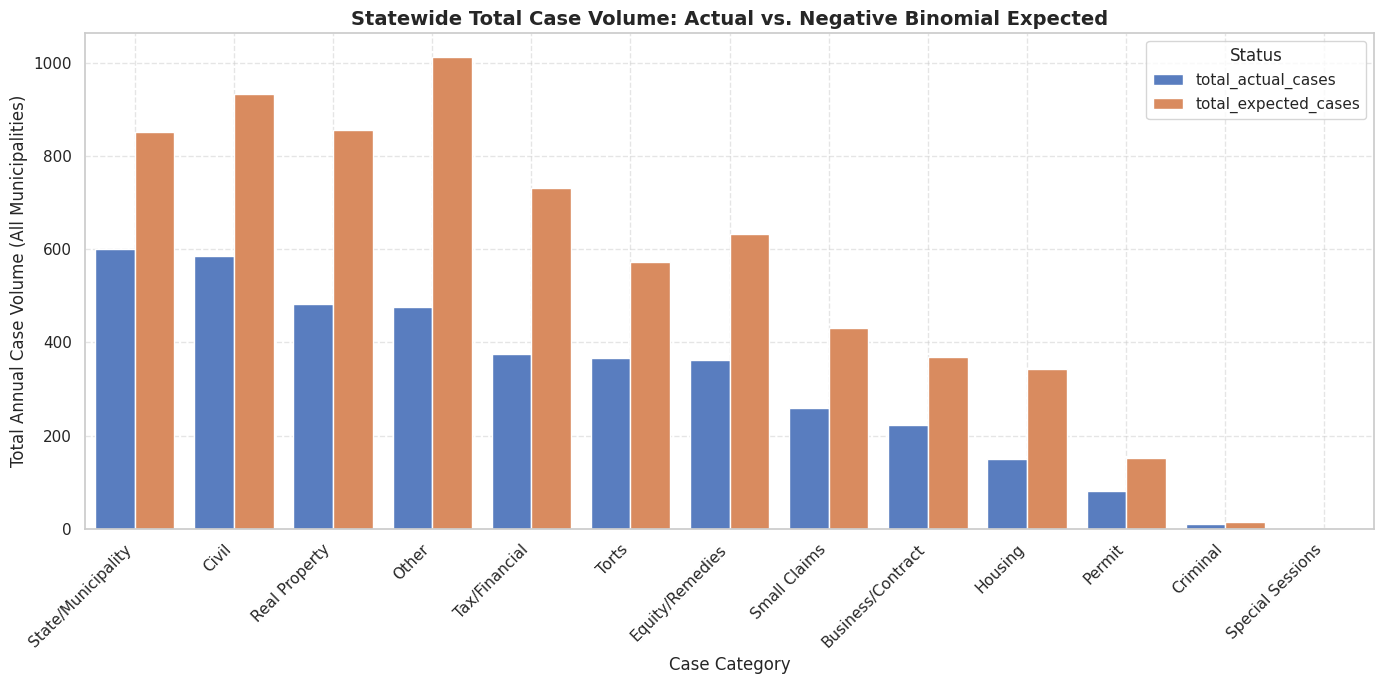

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Aggregate actual cases and expected cases by case category across the state
statewide_comparison = muni_cat_stats.groupby('case_category').agg(
    total_actual_cases=('cases_round', 'sum'),
    total_expected_cases=('expected_cases', 'sum')
).reset_index()

# Calculate the difference and format columns
statewide_comparison['total_expected_cases'] = statewide_comparison['total_expected_cases'].round(1)
statewide_comparison['difference'] = (statewide_comparison['total_actual_cases'] - statewide_comparison['total_expected_cases']).round(1)
statewide_comparison = statewide_comparison.sort_values(by='total_actual_cases', ascending=False)

print("=== STATEWIDE ACTUAL VS. EXPECTED CASES BY CATEGORY ===")
display(statewide_comparison)

# Melt the dataframe for easy plotting with seaborn
melted_comparison = statewide_comparison.melt(
    id_vars='case_category',
    value_vars=['total_actual_cases', 'total_expected_cases'],
    var_name='Case Type Status',
    value_name='Case Volume'
)

# Plotting
plt.figure(figsize=(14, 7))
sns.barplot(
    data=melted_comparison,
    x='case_category',
    y='Case Volume',
    hue='Case Type Status',
    palette='muted'
)
plt.title('Statewide Total Case Volume: Actual vs. Negative Binomial Expected', fontsize=14, fontweight='bold')
plt.xlabel('Case Category', fontsize=12)
plt.ylabel('Total Annual Case Volume (All Municipalities)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()